# 03 -- OU Calibration and Backtest (SYNTHETIC DEMO DATA)

**This notebook runs entirely on synthetic, illustrative data** generated by
`fr_power.demo.synthetic.generate_synthetic_market_data` -- not real ENTSO-E
data. It exists so the pipeline can be demonstrated end-to-end without a live
API token. See [`../reports/conclusions.md`](../reports/conclusions.md) for
the honest, qualitative discussion of the *real* French power market, and for
why no genuine quantitative findings about that market are reported without
one.

To run this notebook against real data instead, run `fr-power fetch` (with a
configured `ENTSOE_API_TOKEN`), then load from `data/raw/` via
`fr_power.data.cache.read_cache` in place of `generate_synthetic_market_data`
below.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from fr_power.backtest.engine import perfect_foresight_backtest, run_backtest
from fr_power.backtest.metrics import block_bootstrap_ci, compute_metrics
from fr_power.config import DEFAULT_CONFIG_PATH, load_config
from fr_power.demo.synthetic import generate_synthetic_market_data
from fr_power.features.build import build_feature_matrix
from fr_power.models.benchmarks import NaivePersistenceForecaster, naive_lag_column
from fr_power.models.gbm import LightGBMForecaster
from fr_power.models.walk_forward import walk_forward_predict
from fr_power.ou.estimate import compute_z_score, estimate_ou

plt.rcParams["figure.figsize"] = (10, 4)
cfg = load_config(DEFAULT_CONFIG_PATH)

CRISIS_START, CRISIS_END = "2020-03-01", "2020-06-01"
data = generate_synthetic_market_data(
    start="2019-01-01", end="2020-07-01", seed=42,
    crisis_start=CRISIS_START, crisis_end=CRISIS_END,
)
matrix = build_feature_matrix(
    day_ahead_prices=data["day_ahead_prices"],
    wind_solar_forecast=data["day_ahead_wind_solar_forecast"],
    load_forecast=data["day_ahead_load_forecast"],
    actual_generation_by_type=data["actual_generation_by_type"],
    net_position=data["cross_border_flows"],
    config=cfg.features,
    weather=data["weather"],
    intraday=data["intraday"],
)
target_col = matrix.attrs["target_column"]
spread = matrix[target_col]

## OU calibration

OUParameters(kappa=0.04038245273497152, mu=1.1465406768624082, sigma=3.004280724358721, half_life=17.16456365612667, stationary_std=10.571318720036375, r_squared=0.9224073176778957, n_observations=10199, method='ols', dt=1.0)


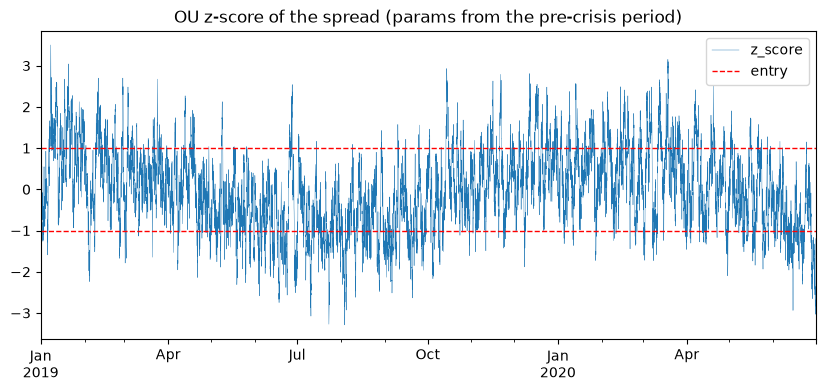

In [2]:
normal_mask = spread.index < CRISIS_START
params = estimate_ou(spread[normal_mask], method=cfg.ou.estimation.method)
print(params)

z = compute_z_score(spread, params)
fig, ax = plt.subplots()
z.plot(ax=ax, linewidth=0.3)
for level, label in [(cfg.ou.optimal_stopping.entry_z_score, "entry"), (-cfg.ou.optimal_stopping.entry_z_score, None)]:
    ax.axhline(level, color="red", linestyle="--", linewidth=1, label=label)
ax.set_title("OU z-score of the spread (params from the pre-crisis period)")
ax.legend()
plt.show()

## Regime split: normal vs. illustrative crisis window

This is the regime-split methodology the real analysis will apply to the actual 2021-2022 energy-crisis / nuclear-outage period -- worked here on the generator's illustrative regime shift so the mechanics are demonstrated end-to-end.

In [3]:
crisis_mask = (spread.index >= CRISIS_START) & (spread.index < CRISIS_END)
params_normal = estimate_ou(spread[normal_mask], method="ols")
params_crisis = estimate_ou(spread[crisis_mask], method="ols")

regime_df = pd.DataFrame(
    {"normal": params_normal.__dict__, "crisis": params_crisis.__dict__}
).T[["kappa", "mu", "sigma", "half_life", "stationary_std", "r_squared", "n_observations"]]
regime_df

,kappa,mu,sigma,half_life,stationary_std,r_squared,n_observations
normal,0.040382,1.146541,3.004281,17.164564,10.571319,0.922407,10199
crisis,0.045479,3.266396,2.957533,15.24113,9.80642,0.91291,2206


## Backtest: combined OU + forecast strategy

In [4]:
naive_lag_col = naive_lag_column(target_col, 168)
feature_cols = [c for c in matrix.columns if not c.startswith("target_")]
factories = {
    "naive": lambda: NaivePersistenceForecaster(naive_lag_col),
    "lightgbm": lambda: LightGBMForecaster(
        n_estimators=150, learning_rate=0.05, num_leaves=15, max_depth=-1,
        min_child_samples=20, subsample=0.8, colsample_bytree=0.8,
        early_stopping_rounds=20, random_seed=42,
    ),
}
predictions = walk_forward_predict(
    matrix, feature_cols, target_col, factories,
    initial_train_hours=180 * 24, retrain_every_hours=90 * 24, test_window_hours=90 * 24,
)

backtest_cfg = cfg.backtest.model_copy(
    update={
        "walk_forward": cfg.backtest.walk_forward.model_copy(
            update={"initial_train_days": 180, "retrain_every_days": 90, "test_window_days": 90}
        )
    }
)
signal_lag = min(cfg.features.spread_lags_hours)
signal_reference = matrix[f"spread_lag_{signal_lag}h"]

results = {
    name: run_backtest(spread, signal_reference, predictions[name], cfg.costs, backtest_cfg, cfg.ou)
    for name in ["naive", "lightgbm"]
}
results["perfect_foresight"] = perfect_foresight_backtest(
    spread, cfg.costs, backtest_cfg, start_index=backtest_cfg.walk_forward.initial_train_days * 24
)

metrics_df = pd.DataFrame({name: compute_metrics(res).to_dict() for name, res in results.items()}).T
metrics_df

,gross_pnl_eur,net_pnl_eur,total_cost_eur,pnl_per_mwh_eur,traded_volume_mwh,n_trades,hit_rate,sharpe_annualized,max_drawdown_eur,turnover_mwh
naive,11131.093726,9853.260856,1277.832870,5.012095,1965.896722,2725.0,0.693211,17.804544,787.986699,1965.896722
lightgbm,20391.638496,19116.601530,1275.036966,9.745436,1961.595332,2856.0,0.864496,32.314569,55.810489,1961.595332
perfect_foresight,74091.659992,69063.909992,5027.750000,8.928754,7735.000000,7735.0,1.000000,78.166444,0.000000,7735.000000


Read `pnl_per_mwh_eur`, `hit_rate` and `sharpe_annualized` relative to `perfect_foresight` (the upper bound), not in isolation -- and keep in mind this is a clean synthetic signal, so these numbers are expected to look better than anything on real, noisy market data.

## Cumulative net PnL

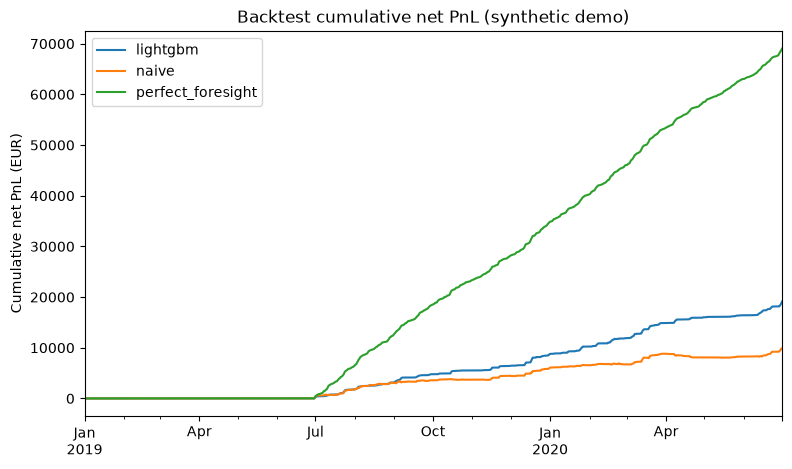

In [5]:
fig, ax = plt.subplots(figsize=(9, 5))
for name in ["lightgbm", "naive", "perfect_foresight"]:
    results[name]["net_pnl_eur"].cumsum().plot(ax=ax, label=name)
ax.set_ylabel("Cumulative net PnL (EUR)")
ax.set_title("Backtest cumulative net PnL (synthetic demo)")
ax.legend()
plt.show()

## Cost-sensitivity sweep

Each point re-runs the full engine at that cost multiplier -- cost changes *which* trades clear the no-trade band, not just the realized cost of a fixed set of trades.

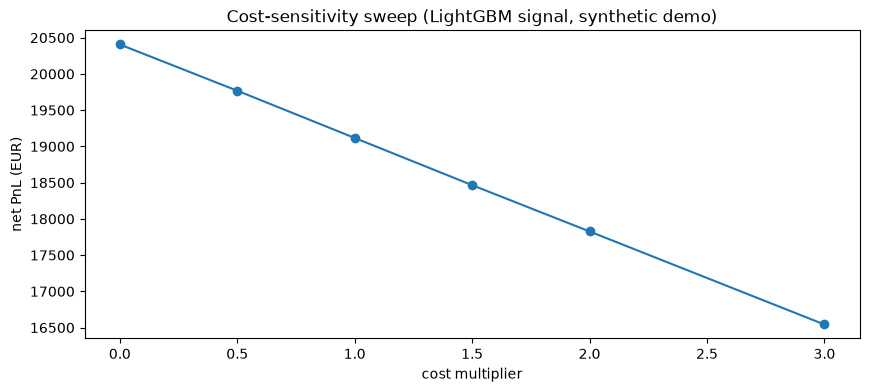

,gross_pnl_eur,net_pnl_eur,total_cost_eur,pnl_per_mwh_eur,traded_volume_mwh,n_trades,hit_rate,sharpe_annualized,max_drawdown_eur,turnover_mwh,cost_multiplier
0,20406.106098,20406.106098,0.000000,10.342133,1973.104218,2949,0.873516,33.210571,52.945777,1973.104218,0.0
1,20408.070934,19768.553979,639.516955,10.046301,1967.744477,2900,0.870345,32.787902,53.651396,1967.744477,0.5
2,20391.638496,19116.601530,1275.036966,9.745436,1961.595332,2856,0.864496,32.314569,55.810489,1961.595332,1.0
3,20367.925778,18465.562129,1902.363648,9.463976,1951.142203,2794,0.863636,31.824164,57.945086,1951.142203,1.5
4,20350.870195,17826.569846,2524.300348,9.180580,1941.769499,2747,0.854387,31.329891,60.465096,1941.769499,2.0
5,20282.014629,16542.577300,3739.437329,8.626438,1917.660169,2650,0.841509,30.258927,64.077046,1917.660169,3.0


In [6]:
sweep_rows = []
for multiplier in cfg.backtest.cost_sensitivity_multipliers:
    swept = run_backtest(
        spread, signal_reference, predictions["lightgbm"], cfg.costs, backtest_cfg, cfg.ou,
        cost_multiplier=multiplier,
    )
    row = compute_metrics(swept).to_dict()
    row["cost_multiplier"] = multiplier
    sweep_rows.append(row)
sweep_df = pd.DataFrame(sweep_rows)

fig, ax = plt.subplots()
ax.plot(sweep_df["cost_multiplier"], sweep_df["net_pnl_eur"], marker="o")
ax.set_xlabel("cost multiplier")
ax.set_ylabel("net PnL (EUR)")
ax.set_title("Cost-sensitivity sweep (LightGBM signal, synthetic demo)")
plt.show()
sweep_df

## Block-bootstrap confidence interval

In [7]:
ci = block_bootstrap_ci(
    results["lightgbm"]["net_pnl_eur"],
    block_length_hours=cfg.backtest.block_bootstrap.block_length_days * 24,
    n_resamples=cfg.backtest.block_bootstrap.n_resamples,
    confidence_level=cfg.backtest.block_bootstrap.confidence_level,
    seed=cfg.project.random_seed,
)
ci

{'net_pnl_eur': (13522.241397601632, 24069.428233784303),
 'sharpe_annualized': (27.75632135060855, 36.41163738726388)}

---

See [`../reports/conclusions.md`](../reports/conclusions.md) for the honest, non-synthetic discussion: what these results would mean on real data, the French-vs-Danish market structure comparison, and the full list of data/modelling limitations.